# BINARY CLASSIFICATION
## Prediksi Diagnosis Kanker Payudara Menggunakan Logistic Regression

### Deskripsi
Proyek ini bertujuan untuk melakukan klasifikasi diagnosis kanker
payudara menggunakan algoritma Logistic Regression.

Dataset yang digunakan adalah Breast Cancer Wisconsin Dataset.

### Tujuan
1. Memahami konsep Binary Classification.
2. Melakukan preprocessing dataset.
3. Membuat model Logistic Regression.
4. Mengukur performa model menggunakan metrik evaluasi.

### Jenis Klasifikasi
Binary Classification (dua kelas):
- Benign (Jinak)
- Malignant (Ganas)

## 1. Import Library

Pada tahap ini dilakukan pemanggilan beberapa library Python
yang dibutuhkan untuk pengolahan data, visualisasi, pembuatan
model Machine Learning, dan evaluasi model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Semua library berhasil diimport!")

Semua library berhasil diimport!


## 2. Membaca Dataset

Dataset Breast Cancer Wisconsin dibaca menggunakan Pandas.

Dataset ini memiliki fitur berupa karakteristik sel tumor,
seperti radius, texture, perimeter, area, dan smoothness.

Kolom diagnosis merupakan target yang akan diprediksi.

In [2]:
df = pd.read_csv("dataset/data.csv")

print("Lima Data Pertama:")
display(df.head())

print("Ukuran Dataset:", df.shape)

Lima Data Pertama:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


Ukuran Dataset: (569, 33)


## 3. Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami struktur dataset,
jumlah data, tipe data, serta kondisi setiap kolom.

Tahap ini membantu mengetahui karakteristik dataset
sebelum dilakukan preprocessing.

In [3]:
print("Informasi Dataset:")
df.info()

print("\nStatistik Deskriptif:")
display(df.describe())

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se      

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


## 4. Memeriksa Missing Value

Missing value merupakan data kosong yang dapat memengaruhi
proses pelatihan model.

Pada tahap ini dilakukan pemeriksaan untuk mengetahui
apakah terdapat nilai kosong dalam dataset.

In [4]:
print("Jumlah Missing Value:")
display(df.isnull().sum())

print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

Jumlah Missing Value:


id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:


Jumlah Data Duplikat:
0


## 5. Visualisasi Distribusi Diagnosis

Visualisasi digunakan untuk melihat jumlah data pada
masing-masing kelas diagnosis.

Kelas B menunjukkan Benign (jinak), sedangkan kelas M
menunjukkan Malignant (ganas).

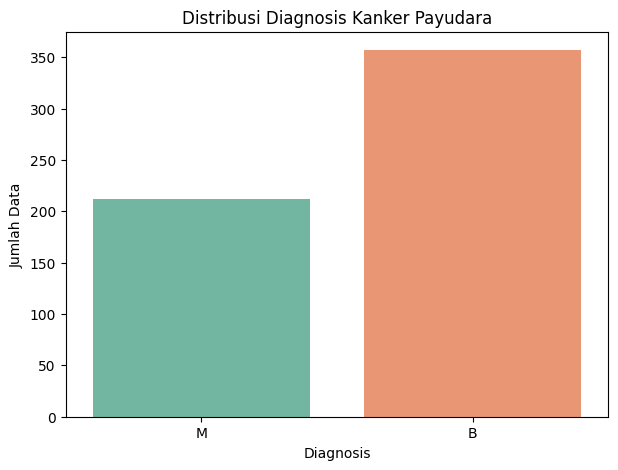

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="diagnosis",
    hue="diagnosis",
    palette="Set2",
    legend=False
)

plt.title("Distribusi Diagnosis Kanker Payudara")
plt.xlabel("Diagnosis")
plt.ylabel("Jumlah Data")

plt.show()

## 6. Data Preprocessing

Data preprocessing merupakan proses mempersiapkan dataset
sebelum digunakan untuk melatih model.

Tahapan yang dilakukan:
1. Menghapus kolom ID karena tidak digunakan sebagai fitur prediksi.
2. Menghapus kolom kosong yang tidak memiliki informasi.
3. Mengubah label diagnosis menjadi angka.

Keterangan:
- B = 0 (Benign)
- M = 1 (Malignant)

In [6]:
df = df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

print("Preprocessing berhasil!")
display(df.head())

Preprocessing berhasil!


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 7. Memisahkan Fitur dan Target

Pada tahap ini dataset dipisahkan menjadi dua bagian.

- X merupakan fitur atau variabel input yang digunakan untuk prediksi.
- y merupakan target atau hasil yang ingin diprediksi.

Target yang digunakan adalah kolom diagnosis.

In [7]:
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

print("Jumlah Fitur:", X.shape[1])
print("Jumlah Target:", y.shape[0])

Jumlah Fitur: 30
Jumlah Target: 569


## 8. Membagi Data Training dan Testing

Dataset dibagi menjadi dua bagian:
- 80% data training untuk melatih model.
- 20% data testing untuk menguji model.

Stratify digunakan agar proporsi kelas pada data training
dan testing tetap terjaga.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah Data Training:", X_train.shape[0])
print("Jumlah Data Testing:", X_test.shape[0])

Jumlah Data Training: 455
Jumlah Data Testing: 114


## 9. Normalisasi Data

Normalisasi dilakukan menggunakan StandardScaler.

Tujuannya adalah menyamakan skala fitur agar proses
pelatihan Logistic Regression berjalan lebih optimal.

Scaler hanya di-fit pada data training untuk menghindari
data leakage.

In [9]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Normalisasi data berhasil!")

Normalisasi data berhasil!


## 10. Pembuatan Model Logistic Regression

Logistic Regression merupakan algoritma Machine Learning
yang dapat digunakan untuk klasifikasi dua kelas.

Pada penelitian ini model digunakan untuk memprediksi
apakah tumor termasuk Benign atau Malignant.

In [10]:
model = LogisticRegression(max_iter=10000)

print("Model Logistic Regression berhasil dibuat!")

Model Logistic Regression berhasil dibuat!


## 11. Training Model

Pada tahap ini model dilatih menggunakan data training.

Model akan mempelajari hubungan antara karakteristik
sel tumor dengan kategori diagnosis.

In [11]:
model.fit(X_train, y_train)

print("Training model berhasil!")

Training model berhasil!


## 12. Melakukan Prediksi

Setelah proses training selesai, model digunakan untuk
memprediksi diagnosis menggunakan data testing.

Hasil prediksi kemudian dibandingkan dengan label
sebenarnya untuk mengetahui performa model.

In [12]:
y_pred = model.predict(X_test)

hasil = pd.DataFrame({
    "Diagnosis Aktual": y_test.values,
    "Hasil Prediksi": y_pred
})

display(hasil.head(10))

,Diagnosis Aktual,Hasil Prediksi
0,0,0
1,1,1
2,0,0
3,1,1
4,0,1
5,0,0
6,1,1
7,0,0
8,0,0
9,0,0


## 13. Evaluasi Model

Evaluasi dilakukan untuk mengetahui kemampuan model
dalam melakukan klasifikasi.

Metrik yang digunakan:
- Accuracy: Persentase prediksi yang benar.
- Precision: Ketepatan prediksi pada suatu kelas.
- Recall: Kemampuan model menemukan data dari suatu kelas.
- F1-Score: Rata-rata harmonis Precision dan Recall.

In [13]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("===== HASIL EVALUASI MODEL =====")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1-Score :", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

===== HASIL EVALUASI MODEL =====
Accuracy : 96.49 %
Precision: 97.5 %
Recall   : 92.86 %
F1-Score : 95.12 %

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## 14. Confusion Matrix

Confusion Matrix digunakan untuk melihat perbandingan
antara hasil prediksi model dengan kondisi sebenarnya.

Confusion Matrix memiliki empat komponen:
- True Negative (TN)
- False Positive (FP)
- False Negative (FN)
- True Positive (TP)

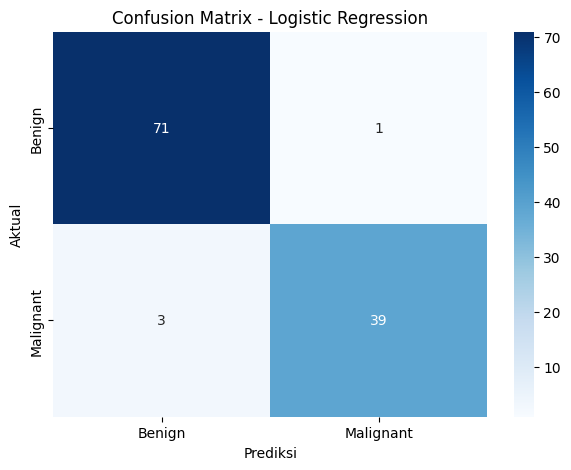

In [14]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

plt.show()

## 15. Kesimpulan

Berdasarkan proses klasifikasi yang telah dilakukan,
model Logistic Regression digunakan untuk memprediksi
diagnosis kanker payudara ke dalam dua kategori,
yaitu Benign dan Malignant.

Evaluasi dilakukan menggunakan Accuracy, Precision,
Recall, F1-Score, dan Confusion Matrix.

Hasil evaluasi menunjukkan kemampuan model dalam
melakukan klasifikasi berdasarkan dataset yang digunakan.

Kesimpulan akhir disesuaikan dengan nilai evaluasi
yang diperoleh setelah program dijalankan.